# Lab 02-06 · Vectors, Matrices and Linear Systems

Companion to chapter [02-06](../../chapters/02-06-vectors-matrices-and-linear-systems.md). Handout: [README.md](README.md).

Run the cells in order. Cells marked **🔮 Predict** ask you to write a prediction *before* running.

In [1]:
import math, sys, time
from pathlib import Path
import numpy as np
import scipy.linalg as sl
import scipy.sparse as sps
import scipy.sparse.linalg as spl
import matplotlib.pyplot as plt
sys.path.insert(0, str(Path.cwd().parents[3] / "tools"))
try:
    from plotstyle import use_style; use_style()
except ImportError:
    pass
np.set_printoptions(precision=4, suppress=True)

## Part 1 — Vectors as arrows and as signals

Example 02-06.1 first: dot product, lengths, angle and projection.

In [2]:
u = np.array([2.0, -1.0, 2.0]); v = np.array([3.0, 0.0, 4.0])
cos_t = u @ v / (np.linalg.norm(u) * np.linalg.norm(v))
p = (u @ v) / (u @ u) * u; e = v - p
print("u.v =", u @ v, " |u| =", np.linalg.norm(u), " |v| =", np.linalg.norm(v))
print(f"angle = {math.degrees(math.acos(cos_t)):.2f} deg;  p = {p};  |e| = {np.linalg.norm(e):.4f};  e.u = {e @ u:.1e}")

u.v = 14.0  |u| = 3.0  |v| = 5.0
angle = 21.04 deg;  p = [ 3.1111 -1.5556  3.1111];  |e| = 1.7951;  e.u = -2.2e-16


**🔮 Predict:** sample $\sin$ and $\cos$ at 1,000 points spread over exactly 3 periods. What is the angle between the two sample vectors?

Then check that the correlation coefficient of two signals equals $\cos\theta$ once their means are removed.

In [3]:
n = 1000
th = 2 * np.pi * 3 * np.arange(n) / n
s_, c_ = np.sin(th), np.cos(th)
print(f"angle between sampled sine and cosine: {math.degrees(math.acos(s_ @ c_ / (np.linalg.norm(s_) * np.linalg.norm(c_)))):.6f} deg")

rng = np.random.default_rng(0)
x = np.sin(th) + 0.5 * rng.standard_normal(n)        # a noisy sine
y = 0.8 * np.sin(th + 0.3) + 0.2 + 0.5 * rng.standard_normal(n)   # a shifted, offset, noisy copy
xc, yc = x - x.mean(), y - y.mean()
print(f"cos(theta) of centered vectors = {xc @ yc / (np.linalg.norm(xc) * np.linalg.norm(yc)):.6f}")
print(f"numpy correlation coefficient  = {np.corrcoef(x, y)[0, 1]:.6f}")

angle between sampled sine and cosine: 90.000000 deg
cos(theta) of centered vectors = 0.618820
numpy correlation coefficient  = 0.618820


## Part 2 — What a matrix product costs

An $n\times n$ product needs $n^3$ multiply–adds.

**🔮 Predict:** by what factor does the time grow when $n$ doubles? (Small sizes are dominated by overheads, and multithreaded libraries add noise, so look at the largest sizes.)

In [4]:
def best_time(f, reps=3):
    ts = []
    for _ in range(reps):
        t0 = time.perf_counter(); f(); ts.append(time.perf_counter() - t0)
    return min(ts)

prev = None
for n in [256, 512, 1024, 2048]:
    A = rng.standard_normal((n, n)); B = rng.standard_normal((n, n))
    t = best_time(lambda: A @ B)
    gf = 2 * n**3 / t / 1e9
    print(f"n = {n:5d}: {t*1e3:8.2f} ms  ({gf:6.1f} GFLOP/s)" + (f"   ratio to previous: {t/prev:4.1f}" if prev else ""))
    prev = t

n =   256:     0.21 ms  ( 157.4 GFLOP/s)
n =   512:     1.14 ms  ( 235.5 GFLOP/s)   ratio to previous:  5.3
n =  1024:     9.92 ms  ( 216.6 GFLOP/s)   ratio to previous:  8.7


n =  2048:    67.99 ms  ( 252.7 GFLOP/s)   ratio to previous:  6.9


## Part 3 — Elimination by hand-written code

Below is Gaussian elimination with optional partial pivoting, written out exactly as in chapter §3.7–3.9. Compare with `numpy.linalg.solve` on Example 02-06.3.

In [5]:
def gauss_solve(A, b, pivot=True):
    A = np.array(A, dtype=float); b = np.array(b, dtype=float); n = len(b)
    for k in range(n - 1):
        if pivot:                                   # bring the largest |entry| to the pivot position
            r = k + np.argmax(np.abs(A[k:, k]))
            if r != k:
                A[[k, r]] = A[[r, k]]; b[[k, r]] = b[[r, k]]
        if A[k, k] == 0:
            raise ZeroDivisionError("zero pivot: exchange rows (or the matrix is singular)")
        for i in range(k + 1, n):
            m = A[i, k] / A[k, k]                   # multiplier l_ik
            A[i, k:] -= m * A[k, k:]
            b[i] -= m * b[k]
    x = np.zeros(n)
    for i in range(n - 1, -1, -1):                  # back substitution
        x[i] = (b[i] - A[i, i + 1:] @ x[i + 1:]) / A[i, i]
    return x

A3 = np.array([[2, 1, -1], [4, 5, -3], [-2, 5, 4.0]])
print("hand-written, no pivoting:", gauss_solve(A3, [1, 5, 20], pivot=False))
print("hand-written, pivoting   :", gauss_solve(A3, [1, 5, 20]))
print("numpy.linalg.solve       :", np.linalg.solve(A3, [1, 5, 20]))

hand-written, no pivoting: [1. 2. 3.]
hand-written, pivoting   : [1. 2. 3.]
numpy.linalg.solve       : [1. 2. 3.]


Now factor once and reuse. SciPy pivots, so its factors satisfy $\mathbf{A} = \mathbf{P}\mathbf{L}\mathbf{U}$ with a permutation: column 1's largest entry is the 4 in row 2, so its $\mathbf{L}$ and $\mathbf{U}$ differ from the hand-computed ones of Example 02-06.3. Both are correct.

In [6]:
lu, piv = sl.lu_factor(A3)                       # one O(n^3) factorization
for b in ([1, 5, 20], [0, 3, 6]):
    print("b =", b, "-> x =", sl.lu_solve((lu, piv), b))   # each solve is O(n^2)
P, L, U = sl.lu(A3)
print("P =\n", P, "\nL =\n", L, "\nU =\n", U)
print("product of pivots:", np.prod(np.diag(U)), " det(A):", np.linalg.det(A3))

b = [1, 5, 20] -> x = [1. 2. 3.]
b = [0, 3, 6] -> x = [-0.5  1.   0. ]
P =
 [[0. 0. 1.]
 [1. 0. 0.]
 [0. 1. 0.]] 
L =
 [[ 1.   0.   0. ]
 [-0.5  1.   0. ]
 [ 0.5 -0.2  1. ]] 
U =
 [[ 4.   5.  -3. ]
 [ 0.   7.5  2.5]
 [ 0.   0.   1. ]]
product of pivots: 30.0  det(A): 29.99999999999999


## Part 4 — Why libraries pivot

Example 02-06.4: $\begin{bmatrix}\varepsilon & 1\\ 1 & 1\end{bmatrix}\mathbf{x} = (1, 2)$, exact $x_1 = 1/(1 - \varepsilon)$.

**🔮 Predict:** at $\varepsilon = 10^{-8}$, about how many correct significant digits does the unpivoted $x_1$ keep?

In [7]:
print(f"{'eps':>8s} {'x1 (no pivot)':>22s} {'rel. error':>11s} {'x1 (pivot)':>20s} {'rel. error':>11s}")
for eps in [1e-4, 1e-8, 1e-12, 1e-16, 1e-17]:
    A = [[eps, 1], [1, 1]]; b = [1, 2]; true = 1 / (1 - eps)
    xn = gauss_solve(A, b, pivot=False)[0]; xp = gauss_solve(A, b, pivot=True)[0]
    print(f"{eps:8.0e} {xn:22.16f} {abs(xn - true) / true:11.1e} {xp:20.16f} {abs(xp - true) / true:11.1e}")

     eps          x1 (no pivot)  rel. error           x1 (pivot)  rel. error
   1e-04     1.0001000100012813     2.8e-13   1.0001000100010002     2.2e-16
   1e-08     1.0000000050247593     5.0e-09   1.0000000099999999     2.2e-16
   1e-12     0.9999778782798785     2.2e-05   1.0000000000010001     0.0e+00
   1e-16     2.2204460492503131     1.2e+00   1.0000000000000000     2.2e-16
   1e-17     0.0000000000000000     1.0e+00   1.0000000000000000     0.0e+00


## Part 5 — Nodal analysis by stamping

A small "simulator": each element adds its stamp to $\mathbf{G}$ and $\mathbf{i}$ (chapter §3.10). Node 0 is ground and is dropped.

In [8]:
def nodal(n_nodes, resistors, isources):
    G = np.zeros((n_nodes, n_nodes)); i = np.zeros(n_nodes)
    for a, b, R in resistors:                       # resistor stamp
        g = 1 / R
        for p, q, s in ((a, a, g), (b, b, g), (a, b, -g), (b, a, -g)):
            if p and q:
                G[p - 1, q - 1] += s
    for frm, to, I in isources:                     # current I flows from node 'frm' into node 'to'
        if to: i[to - 1] += I
        if frm: i[frm - 1] -= I
    return G, i

# Example 02-06.5 (ohms and amps)
G, i = nodal(3, [(1, 2, 1e3), (1, 3, 2e3), (2, 0, 1e3), (2, 3, 2e3), (3, 0, 500)], [(0, 1, 10e-3)])
v = np.linalg.solve(G, i)
print("G (mS) =\n", G * 1e3)
print("node voltages (V):", v, "   ngspice nodal.cir gives 10.7407, 4.81481, 2.59259")
print(f"source power = {v[0] * 10:.2f} mW")

# Problem 02-06.11
G, i = nodal(2, [(1, 0, 2e3), (1, 2, 1e3), (2, 0, 4e3)], [(0, 1, 5e-3), (2, 0, 1e-3)])
print("Problem 11 node voltages (V):", np.linalg.solve(G, i))

# Without a ground connection the matrix is singular (Problem 02-06.13)
G3, _ = nodal(3, [(1, 2, 1e3), (2, 3, 1e3), (1, 3, 2e3)], [])
print("floating triangle: row sums =", G3.sum(axis=1), " rank =", np.linalg.matrix_rank(G3), "of 3")

G (mS) =
 [[ 1.5 -1.  -0.5]
 [-1.   2.5 -0.5]
 [-0.5 -0.5  3. ]]
node voltages (V): [10.7407  4.8148  2.5926]    ngspice nodal.cir gives 10.7407, 4.81481, 2.59259
source power = 107.41 mW
Problem 11 node voltages (V): [6. 4.]
floating triangle: row sums = [0. 0. 0.]  rank = 2 of 3


## Part 6 — An on-chip power grid

A 20×20 mesh of nodes, each joined to its neighbors by 0.1 Ω of metal, each drawing 1 mA from the supply. Supply pads hold some nodes at $V_{DD}$. Work with the drop $d = V_{DD} - v$: then $\mathbf{G}\mathbf{d} = \mathbf{i}$, with the pad nodes removed (they are the "ground" of the drop problem).

**🔮 Predict:** where is the worst drop with a single pad at one corner? By what factor does adding pads at the other three corners reduce it?

one corner pad : worst drop 77.85 mV at (row, col) (19, 19)
four corner pads: worst drop 15.06 mV at (row, col) (10, 9)
reduction factor: 5.170
G is 399 x 399 with 1915 nonzeros (4.8 per row, 1.20% of entries)


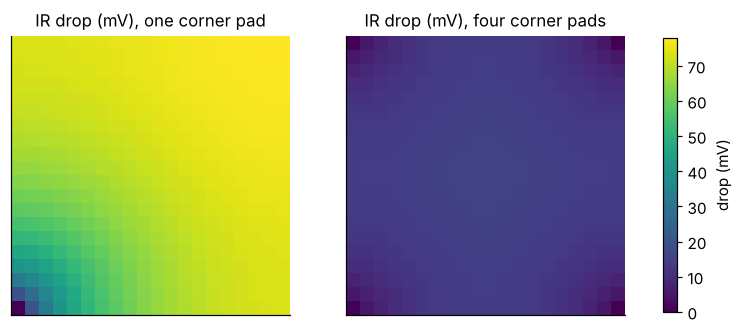

In [9]:
def grid_drop(N, R, I, pads):
    n = N * N; idx = lambda r, c: r * N + c
    rows, cols, vals = [], [], []
    g = 1 / R
    def stamp(a, b):
        rows.extend([a, b, a, b]); cols.extend([a, b, b, a]); vals.extend([g, g, -g, -g])
    for r in range(N):
        for c in range(N):
            if c + 1 < N: stamp(idx(r, c), idx(r, c + 1))
            if r + 1 < N: stamp(idx(r, c), idx(r + 1, c))
    G = sps.csr_matrix((vals, (rows, cols)), shape=(n, n))   # duplicate entries are summed
    pad_ids = {idx(r, c) for r, c in pads}
    keep = np.array([k for k in range(n) if k not in pad_ids])
    Gr = G[keep][:, keep].tocsc()
    d = np.zeros(n); d[keep] = spl.spsolve(Gr, np.full(len(keep), I))
    return d.reshape(N, N), Gr

N, R, I = 20, 0.1, 1e-3
d1, G1 = grid_drop(N, R, I, [(0, 0)])
d4, _ = grid_drop(N, R, I, [(0, 0), (0, N - 1), (N - 1, 0), (N - 1, N - 1)])
print(f"one corner pad : worst drop {d1.max()*1e3:.2f} mV at (row, col) {tuple(int(k) for k in np.unravel_index(d1.argmax(), d1.shape))}")
print(f"four corner pads: worst drop {d4.max()*1e3:.2f} mV at (row, col) {tuple(int(k) for k in np.unravel_index(d4.argmax(), d4.shape))}")
print(f"reduction factor: {d1.max() / d4.max():.3f}")
print(f"G is {G1.shape[0]} x {G1.shape[1]} with {G1.nnz} nonzeros ({G1.nnz / G1.shape[0]:.1f} per row, "
      f"{100 * G1.nnz / G1.shape[0]**2:.2f}% of entries)")

fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, d, title in ((axes[0], d1, "one corner pad"), (axes[1], d4, "four corner pads")):
    im = ax.imshow(d * 1e3, cmap="viridis", origin="lower", vmin=0, vmax=d1.max() * 1e3)
    ax.set_title(f"IR drop (mV), {title}"); ax.set_xticks([]); ax.set_yticks([])
fig.colorbar(im, ax=axes, shrink=0.85, label="drop (mV)")
plt.show()

**🔮 Predict:** for a grid with $N^2$ nodes, how should the time of a *dense* solve grow as $N$ doubles? And the sparse solve?

In [10]:
for N in [20, 40, 60]:
    _, Gr = grid_drop(N, 0.1, 1e-3, [(0, 0)])
    b = np.full(Gr.shape[0], 1e-3)
    ts = best_time(lambda: spl.spsolve(Gr, b))
    Gd = Gr.toarray()
    td = best_time(lambda: np.linalg.solve(Gd, b))
    print(f"N = {N:3d} ({Gr.shape[0]:5d} unknowns): sparse {ts*1e3:8.2f} ms, dense {td*1e3:8.2f} ms, "
          f"dense memory {Gd.nbytes/1e6:7.1f} MB")

N =  20 (  399 unknowns): sparse     0.73 ms, dense     1.18 ms, dense memory     1.3 MB


N =  40 ( 1599 unknowns): sparse     2.97 ms, dense    20.70 ms, dense memory    20.5 MB


N =  60 ( 3599 unknowns): sparse     7.97 ms, dense   207.15 ms, dense memory   103.6 MB


## Part 7 — ngspice

From the repository root, run `python tools/run_spice.py 02-06`:

- `nodal.cir`: Example 02-06.5 (10.74, 4.815 and 2.593 V), Problem 02-06.11 (6 V, 4 V) and Problem 02-06.13 (1 V and 0.5 V; with the 2 V source, 1 V and a source current reported as −2 mA, SPICE's sign convention).
- `power_rail.cir`: Problem 02-06.14 (60 mV worst drop fed from one end, 18 mV from both ends).

## Your turn

1. Move the single pad of Part 6 to the middle of one edge, then to the center of the grid. Predict the order of the three worst drops before running.
2. In Part 3, run `gauss_solve` without pivoting on the matrix of Problem 02-06.7. What happens, and why does pivoting fix it?
3. Change Example 02-06.5's $R_e$ to 1 MΩ (almost open). Predict which node voltage changes most, then check.